# 04. Bốn phương án neo A, B, C, D

Lần chạy chốt (notebook `03-Tien_xu_ly_va_thuc_nghiem_chinh.ipynb`) chỉ đo chi phí tính toán của bốn phương án neo, không đo sai số.  Sổ tay này thực hiện cho việc tính toán này.

Bốn phương án được so sánh trên cùng dữ liệu đã tiền xử lý của lần chạy chốt, cùng số hạt giống, cùng ngân sách huấn luyện:

- A lấy giá trị tại bước cuối của cửa sổ, đúng như NLinear gốc. Khi bước cuối không có phép đo thật, giá trị này bằng không, tức bằng trung bình tập huấn luyện.
- B lấy phép đo thật gần nhất, bất kể cách xa bao nhiêu giờ.
- C nhân giá trị của B với hệ số suy giảm theo khoảng trễ, một tham số dùng chung cho mọi kênh.
- D giống C nhưng mỗi kênh có tham số suy giảm riêng.

Giả thuyết nghiên cứu (kì vọng trong kế hoạch tuần 1) dự đoán thứ tự B tốt hơn A, và C hoặc D tốt hơn B. Nếu thứ tự thực nghiệm khác dự đoán thì phải báo cáo đúng như đo được.

> **Vị trí trong chuỗi tái lập:** notebook 04 trên tổng số 31. Thứ tự chạy và sơ đồ phụ thuộc nằm trong `README.md`.
>
> **Cần chạy trước:** 03-Tien_xu_ly_va_thuc_nghiem_chinh.
>
> **Thư mục kết quả:** `Output/processed/bo_sung_04_neo_abcd/`.
>
> **Mã định danh nội bộ:** `W2_04`. Mã này còn xuất hiện trong tên khóa JSON, tên hình và nhật ký chạy; nó được giữ nguyên để không phá phép đối chiếu chéo và mã băm của bản khai báo trước.

## 1. Tham số và đường dẫn

In [1]:
#@title Tham số chạy { display-mode: "form" }
PROJECT_DIR = "/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4"  #@param {type:"string"}
READ_TAG = "chot"  #@param {type:"string"}
RUN_TAG = "bo_sung_04_neo_abcd"  #@param {type:"string"}
DANH_SACH_NEO = "A,B,C,D"  #@param {type:"string"}
SEQ_LEN = 36     #@param {type:"integer"}
PRED_LEN = 12    #@param {type:"integer"}
N_SEEDS = 3      #@param {type:"integer"}
EPOCHS = 60      #@param {type:"integer"}
PATIENCE = 10    #@param {type:"integer"}
BATCH = 128      #@param {type:"integer"}
LR = 1e-3        #@param {type:"number"}

NEO = [t.strip() for t in DANH_SACH_NEO.split(",") if t.strip()]

import os, sys, json, time, random, datetime, platform, importlib, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
else:
    PROJECT_DIR = os.environ.get("P12_PROJECT", "./AIO2026_Conquer_M4_DLinear_NLinear_Slot4")

PROJECT = Path(PROJECT_DIR)
OUT = PROJECT / "Output"
# Đọc dữ liệu đã tiền xử lý của lần chạy chốt, ghi kết quả sang một thư mục con riêng.
PROC = OUT / "processed" / READ_TAG
RUN_DIR = OUT / "processed" / RUN_TAG
RUNS = RUN_DIR / "runs"
FIGS = RUN_DIR / "figures"
LOGS = RUN_DIR / "logs"
for d in (RUN_DIR, RUNS, FIGS, LOGS):
    d.mkdir(parents=True, exist_ok=True)

assert (PROC / "meta.json").exists(), (
    "Không thấy dữ liệu đã tiền xử lý trong " + str(PROC) +
    ". Hãy chạy notebook 03-Tien_xu_ly_va_thuc_nghiem_chinh trước.")
meta = json.loads((PROC / "meta.json").read_text())
channels = meta["channels"]
EPS = 1e-8

print("Thư mục đọc :", PROC)
print("Thư mục ghi :", RUN_DIR)
print("Số kênh     :", len(channels), "| ngưỡng cắt sigma của lần chạy nguồn:", meta["clip_sigma"])

Mounted at /content/drive
Thư mục đọc : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot
Thư mục ghi : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/bo_sung_04_neo_abcd
Số kênh     : 37 | ngưỡng cắt sigma của lần chạy nguồn: 0.0


In [2]:
REQUIRED = {"numpy": "1.24.0", "torch": "2.0.0", "matplotlib": "3.7.0", "scipy": "1.10.0"}


def ver_tuple(v):
    out = []
    for part in str(v).split(".")[:3]:
        digits = "".join(ch for ch in part if ch.isdigit())
        out.append(int(digits) if digits else 0)
    return tuple(out + [0] * (3 - len(out)))


missing = []
for name, floor in REQUIRED.items():
    try:
        mod = importlib.import_module(name)
        if ver_tuple(mod.__version__) < ver_tuple(floor):
            missing.append(name + ">=" + floor)
    except ImportError:
        missing.append(name + ">=" + floor)

if missing:
    print("Cài bổ sung:", " ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + missing, check=True)

import numpy as np
import torch
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

ENV = {
    "timestamp": datetime.datetime.now().isoformat(timespec="seconds"),
    "run_tag": RUN_TAG,
    "read_tag": READ_TAG,
    "python": platform.python_version(),
    "numpy": np.__version__,
    "torch": torch.__version__,
    "matplotlib": matplotlib.__version__,
    "scipy": scipy.__version__,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
}
stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
(LOGS / ("env_" + stamp + ".json")).write_text(json.dumps(ENV, ensure_ascii=False, indent=2))
for k, v in ENV.items():
    print(k.ljust(12), v)

timestamp    2026-10-14T18:06:58
run_tag      bo_sung_04_neo_abcd
read_tag     chot
python       3.13.15
numpy        2.1.3
torch        2.11.0+cu130
matplotlib   3.10.0
scipy        1.16.3
gpu          Tesla T4


In [3]:
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#000000"]

matplotlib.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "legend.frameon": False,
    "lines.linewidth": 1.4,
    "axes.prop_cycle": matplotlib.cycler(color=PALETTE),
    "figure.constrained_layout.use": True,
})


def luu_hinh(fig, ten):
    duong = FIGS / ten
    fig.savefig(duong)
    print("Đã lưu", duong)
    return duong


print("Đã đặt quy ước trình bày hình")

Đã đặt quy ước trình bày hình


## 2. Mô hình và chỉ số

Một lớp duy nhất bao trùm cả hai họ mô hình. Phép so sánh bốn phương án neo vì thế chỉ khác nhau đúng một tham số, không có nhánh mã nào lệch nhau ở chỗ không liên quan. Hàm mất mát và chỉ số đánh giá chỉ tính trên các ô có phép đo thật.

In [4]:
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def moving_avg(x, kernel_size=25):
    front = x[:, :1, :].repeat(1, (kernel_size - 1) // 2, 1)
    end = x[:, -1:, :].repeat(1, kernel_size - (kernel_size - 1) // 2 - 1, 1)
    xp = torch.cat([front, x, end], dim=1).permute(0, 2, 1)
    return F.avg_pool1d(xp, kernel_size=kernel_size, stride=1).permute(0, 2, 1)


def last_observed(x, mask):
    # Trả về giá trị quan sát thật gần nhất và số giờ đã trôi qua kể từ phép đo đó.
    B, Lx, C = x.shape
    pos = torch.arange(Lx, device=x.device).view(1, Lx, 1).expand(B, Lx, C)
    idx = torch.where(mask > 0, pos, torch.full_like(pos, -1))
    t_star = idx.max(dim=1).values
    has = t_star >= 0
    val = torch.gather(x, 1, t_star.clamp(min=0).unsqueeze(1)).squeeze(1)
    val = torch.where(has, val, torch.zeros_like(val))
    dt = torch.where(has, (Lx - 1 - t_star).float(), torch.full_like(val, float(Lx)))
    return val, dt


class LinearFamily(nn.Module):
    # Một lớp bao trùm cả DLinear và NLinear, bốn phương án neo chọn bằng tham số anchor.
    def __init__(self, seq_len, pred_len, n_channels, kind="nlinear", anchor="A",
                 use_mask_channel=True, kernel_size=25):
        super().__init__()
        assert kind in ("dlinear", "nlinear")
        assert anchor in ("A", "B", "C", "D")
        self.L, self.H, self.C = seq_len, pred_len, n_channels
        self.kind, self.anchor = kind, anchor
        self.use_mask_channel = use_mask_channel
        self.kernel_size = kernel_size
        in_dim = seq_len * (2 if use_mask_channel else 1)
        if kind == "dlinear":
            self.lin_seasonal = nn.Linear(in_dim, pred_len)
            self.lin_trend = nn.Linear(in_dim, pred_len)
        else:
            self.lin = nn.Linear(in_dim, pred_len)
        if anchor == "C":
            self.w_decay = nn.Parameter(torch.zeros(1))
        elif anchor == "D":
            self.w_decay = nn.Parameter(torch.zeros(n_channels))

    def compute_anchor(self, x, mask):
        if self.anchor == "A":
            return x[:, -1, :]
        val, dt = last_observed(x, mask)
        if self.anchor == "B":
            return val
        rate = F.softplus(self.w_decay)
        return torch.exp(-rate.view(1, -1) * dt) * val

    def _flatten(self, x, mask):
        B, Lx, C = x.shape
        xt = x.permute(0, 2, 1).reshape(B * C, Lx)
        if not self.use_mask_channel:
            return xt
        mt = mask.permute(0, 2, 1).reshape(B * C, Lx).float()
        return torch.cat([xt, mt], dim=-1)

    def forward(self, x, mask):
        B, Lx, C = x.shape
        if self.kind == "nlinear":
            a = self.compute_anchor(x, mask)
            z = self.lin(self._flatten(x - a.unsqueeze(1), mask))
            y = z.view(B, C, self.H).permute(0, 2, 1) + a.unsqueeze(1)
        else:
            trend = moving_avg(x, self.kernel_size)
            zs = self.lin_seasonal(self._flatten(x - trend, mask))
            zt = self.lin_trend(self._flatten(trend, mask))
            y = (zs + zt).view(B, C, self.H).permute(0, 2, 1)
        return y


class Persistence(nn.Module):
    # Đường cơ sở không tham số: giữ nguyên phép đo thật gần nhất cho mọi bước tương lai.
    def __init__(self, pred_len):
        super().__init__()
        self.H = pred_len

    def forward(self, x, mask):
        val, _ = last_observed(x, mask)
        return val.unsqueeze(1).repeat(1, self.H, 1)


def dat_hat_giong(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def tong_theo_ho_so(y_hat, y, m):
    m = m.astype(np.float64)
    se = (m * (y_hat - y) ** 2).reshape(len(m), -1).sum(axis=1)
    ae = (m * np.abs(y_hat - y)).reshape(len(m), -1).sum(axis=1)
    dem = m.reshape(len(m), -1).sum(axis=1)
    return se, ae, dem


def khoang_tin_cay(se, ae, dem, n_boot=2000, seed=0, alpha=0.05):
    # Lấy mẫu lại ở cấp bệnh nhân, không phải cấp điểm đo, vì các điểm trong cùng
    # Một hồ sơ không độc lập với nhau.
    rng = np.random.default_rng(seed)
    N = len(dem)
    mses, maes = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, N, N)
        mau = dem[idx].sum() + EPS
        mses[b] = se[idx].sum() / mau
        maes[b] = ae[idx].sum() / mau
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)
    return {
        "mse": float(se.sum() / (dem.sum() + EPS)),
        "mse_ci": [float(np.percentile(mses, lo)), float(np.percentile(mses, hi))],
        "mae": float(ae.sum() / (dem.sum() + EPS)),
        "mae_ci": [float(np.percentile(maes, lo)), float(np.percentile(maes, hi))],
        "mae_theo_ho_so": float(np.mean(ae / np.maximum(dem, 1.0))),
    }


print("Thiết bị tính toán:", DEVICE)

Thiết bị tính toán: cuda


In [5]:
def nap_lat(ten, L, H):
    d = np.load(PROC / (ten + ".npz"))
    Xd, Md = d["X"], d["M"]
    assert Xd.shape[1] >= L + H, "Lưới thời gian ngắn hơn L cộng H"
    x, mxx = Xd[:, :L], Md[:, :L]
    y, myy = Xd[:, L:L + H], Md[:, L:L + H]
    giu = myy.reshape(len(myy), -1).sum(axis=1) > 0
    return (torch.from_numpy(x[giu]).float(), torch.from_numpy(mxx[giu]).float(),
            torch.from_numpy(y[giu]).float(), torch.from_numpy(myy[giu]).float(),
            int(giu.sum()), int((~giu).sum()))


SPLITS = {}
for ten in ("train", "val", "test"):
    x, mxx, y, myy, giu, bo = nap_lat(ten, SEQ_LEN, PRED_LEN)
    SPLITS[ten] = TensorDataset(x, mxx, y, myy)
    print(ten.ljust(6), "giữ", giu, "hồ sơ, bỏ", bo, "hồ sơ không có mục tiêu quan sát thật")

N_CH = SPLITS["train"].tensors[0].shape[-1]
print("Số kênh:", N_CH)

train  giữ 5559 hồ sơ, bỏ 41 hồ sơ không có mục tiêu quan sát thật
val    giữ 794 hồ sơ, bỏ 6 hồ sơ không có mục tiêu quan sát thật
test   giữ 1585 hồ sơ, bỏ 15 hồ sơ không có mục tiêu quan sát thật
Số kênh: 37


In [6]:
def tinh_mat_mat(pred, y, m, loai, delta=1.0):
    # Mọi hàm mất mát chỉ tính trên các ô có phép đo thật, mẫu số là tổng mặt nạ.
    if loai == "mse":
        thanh_phan = (pred - y) ** 2
    elif loai == "mae":
        thanh_phan = (pred - y).abs()
    elif loai == "huber":
        thanh_phan = F.huber_loss(pred, y, reduction="none", delta=delta)
    else:
        raise ValueError("Không biết loại mất mát " + str(loai))
    return (m * thanh_phan).sum() / (m.sum() + EPS)


def chay_mot_cau_hinh(kind, anchor="A", seed=0, nhan=None, loai_mat_mat="mse",
                      huber_delta=1.0, epochs=None, patience=None, ghi_file=True):
    """Huấn luyện một cấu hình, đánh giá trên tập kiểm tra, ghi kết quả ra thư mục runs."""
    epochs = EPOCHS if epochs is None else epochs
    patience = PATIENCE if patience is None else patience
    dat_hat_giong(seed)

    if kind == "persistence":
        model = Persistence(PRED_LEN).to(DEVICE)
        so_tham_so = 0
    else:
        model = LinearFamily(SEQ_LEN, PRED_LEN, N_CH, kind=kind, anchor=anchor).to(DEVICE)
        so_tham_so = sum(p.numel() for p in model.parameters() if p.requires_grad)

    loaders = {k: DataLoader(v, batch_size=BATCH, shuffle=(k == "train"))
               for k, v in SPLITS.items()}

    t0 = time.time()
    tot_nhat, trang_thai, xau, lich_su = float("inf"), None, 0, []
    val_mse_luc_tot_nhat = None
    if kind != "persistence":
        opt = torch.optim.Adam(model.parameters(), lr=LR)
        for ep in range(epochs):
            model.train()
            for x, mxx, y, myy in loaders["train"]:
                x, mxx, y, myy = [t.to(DEVICE) for t in (x, mxx, y, myy)]
                opt.zero_grad()
                mat_mat = tinh_mat_mat(model(x, mxx), y, myy, loai_mat_mat, huber_delta)
                mat_mat.backward()
                opt.step()
            model.eval()
            with torch.no_grad():
                tu = tu_mse = mau = 0.0
                for x, mxx, y, myy in loaders["val"]:
                    x, mxx, y, myy = [t.to(DEVICE) for t in (x, mxx, y, myy)]
                    p = model(x, mxx)
                    if loai_mat_mat == "mse":
                        tp = (p - y) ** 2
                    elif loai_mat_mat == "mae":
                        tp = (p - y).abs()
                    else:
                        tp = F.huber_loss(p, y, reduction="none", delta=huber_delta)
                    tu += float((myy * tp).sum())
                    tu_mse += float((myy * (p - y) ** 2).sum())
                    mau += float(myy.sum())
                val_loss = tu / (mau + EPS)
                val_mse = tu_mse / (mau + EPS)
            lich_su.append(val_loss)
            # Dừng sớm theo đúng hàm mất mát đang huấn luyện, để phép so sánh không thiên lệch.
            if val_loss < tot_nhat - 1e-6:
                tot_nhat, xau, val_mse_luc_tot_nhat = val_loss, 0, val_mse
                trang_thai = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                xau += 1
                if xau >= patience:
                    break
        if trang_thai is not None:
            model.load_state_dict(trang_thai)
    thoi_gian = time.time() - t0

    model.eval()
    du_bao = []
    with torch.no_grad():
        for x, mxx, y, myy in loaders["test"]:
            du_bao.append(model(x.to(DEVICE), mxx.to(DEVICE)).cpu().numpy())
    yhat = np.concatenate(du_bao)
    y_te = SPLITS["test"].tensors[2].numpy()
    my_te = SPLITS["test"].tensors[3].numpy()
    se, ae, dem = tong_theo_ho_so(yhat, y_te, my_te)
    ket = khoang_tin_cay(se, ae, dem, seed=seed)

    ten = nhan or (kind + ("_" + anchor if kind == "nlinear" else "") +
                   "_" + loai_mat_mat + "_s" + str(seed))
    payload = {"name": ten, "kind": kind, "anchor": anchor, "seed": seed,
               "loai_mat_mat": loai_mat_mat, "huber_delta": huber_delta,
               "seq_len": SEQ_LEN, "pred_len": PRED_LEN, "n_params": so_tham_so,
               "protocol": meta["protocol"], "read_tag": READ_TAG, "run_tag": RUN_TAG,
               "val_loss": tot_nhat if tot_nhat < float("inf") else None,
               "val_mse_obs": val_mse_luc_tot_nhat,
               "train_time_sec": round(thoi_gian, 2), "device": DEVICE,
               "history": lich_su, "test": ket, "env": ENV}
    if ghi_file:
        (RUNS / (ten + ".json")).write_text(json.dumps(payload, ensure_ascii=False, indent=2))
        np.savez_compressed(RUNS / (ten + "_patient_sums.npz"), se=se, ae=ae, n=dem)
    print(ten.ljust(30), "MSE_obs", round(ket["mse"], 4), "| MAE_obs", round(ket["mae"], 4),
          "|", int(thoi_gian), "giây |", so_tham_so, "tham số")
    return payload


print("Đã định nghĩa hàm huấn luyện")

Đã định nghĩa hàm huấn luyện


In [7]:
def hieu_so_bat_cap(se_a, ae_a, se_b, ae_b, dem, n_boot=2000, seed=0, alpha=0.05):
    """Khoảng tin cậy cho hiệu số hai mô hình, lấy mẫu lại cùng một danh sách bệnh nhân."""
    rng = np.random.default_rng(seed)
    N = len(dem)
    d_mse, d_mae = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, N, N)
        mau = dem[idx].sum() + EPS
        d_mse[b] = (se_a[idx].sum() - se_b[idx].sum()) / mau
        d_mae[b] = (ae_a[idx].sum() - ae_b[idx].sum()) / mau
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)
    mau_that = dem.sum() + EPS
    return {
        "hieu_mse": float((se_a.sum() - se_b.sum()) / mau_that),
        "hieu_mse_ci": [float(np.percentile(d_mse, lo)), float(np.percentile(d_mse, hi))],
        "hieu_mae": float((ae_a.sum() - ae_b.sum()) / mau_that),
        "hieu_mae_ci": [float(np.percentile(d_mae, lo)), float(np.percentile(d_mae, hi))],
        "p_hai_phia_mse": float(2 * min((d_mse <= 0).mean(), (d_mse >= 0).mean())),
        "p_hai_phia_mae": float(2 * min((d_mae <= 0).mean(), (d_mae >= 0).mean())),
        "mau_bootstrap_mse": d_mse,
        "mau_bootstrap_mae": d_mae,
    }


print("Đã định nghĩa hàm kiểm định bắt cặp")

Đã định nghĩa hàm kiểm định bắt cặp


## 3. Chạy bốn phương án neo

Mỗi phương án chạy ba hạt giống. Ba hạt giống đủ để đo độ lệch chuẩn khởi tạo, vì lần chạy chốt cho thấy độ lệch này rất nhỏ, khoảng 0,0003. Ngân sách tính toán còn lại được dồn cho phép bắt cặp theo bệnh nhân, nơi biến thiên thật sự lớn.

In [8]:
ket_qua = {}
t0 = time.time()
for neo in NEO:
    for seed in range(N_SEEDS):
        p = chay_mot_cau_hinh("nlinear", anchor=neo, seed=seed,
                              nhan="nlinear_neo" + neo + "_s" + str(seed))
        ket_qua.setdefault(neo, []).append(p)
print("Tổng thời gian:", round((time.time() - t0) / 60, 1), "phút")

nlinear_neoA_s0                MSE_obs 0.4877 | MAE_obs 0.4709 | 12 giây | 876 tham số
nlinear_neoA_s1                MSE_obs 0.4882 | MAE_obs 0.4717 | 6 giây | 876 tham số
nlinear_neoA_s2                MSE_obs 0.4882 | MAE_obs 0.4725 | 7 giây | 876 tham số
nlinear_neoB_s0                MSE_obs 0.4357 | MAE_obs 0.4368 | 8 giây | 876 tham số
nlinear_neoB_s1                MSE_obs 0.4361 | MAE_obs 0.4372 | 8 giây | 876 tham số
nlinear_neoB_s2                MSE_obs 0.4363 | MAE_obs 0.4378 | 7 giây | 876 tham số
nlinear_neoC_s0                MSE_obs 0.4507 | MAE_obs 0.4459 | 12 giây | 877 tham số
nlinear_neoC_s1                MSE_obs 0.4508 | MAE_obs 0.4455 | 12 giây | 877 tham số
nlinear_neoC_s2                MSE_obs 0.4508 | MAE_obs 0.4446 | 12 giây | 877 tham số
nlinear_neoD_s0                MSE_obs 0.4425 | MAE_obs 0.4399 | 12 giây | 913 tham số
nlinear_neoD_s1                MSE_obs 0.4426 | MAE_obs 0.4391 | 12 giây | 913 tham số
nlinear_neoD_s2                MSE_obs 0.4432 | 

In [9]:
tong_hop = {}
for neo, ds in ket_qua.items():
    mse = np.array([d["test"]["mse"] for d in ds])
    mae = np.array([d["test"]["mae"] for d in ds])
    tong_hop[neo] = {
        "mse_trung_binh": float(mse.mean()),
        "mse_do_lech_chuan": float(mse.std(ddof=1)) if len(mse) > 1 else 0.0,
        "mae_trung_binh": float(mae.mean()),
        "so_tham_so": ds[0]["n_params"],
        "giay_trung_binh": float(np.mean([d["train_time_sec"] for d in ds])),
        "cac_gia_tri_mse": [float(v) for v in mse],
    }
    print("Neo", neo, "| MSE", round(float(mse.mean()), 6),
          "+/-", round(float(mse.std(ddof=1)) if len(mse) > 1 else 0.0, 6),
          "| MAE", round(float(mae.mean()), 6),
          "|", ds[0]["n_params"], "tham số",
          "|", round(float(np.mean([d["train_time_sec"] for d in ds])), 1), "giây")

thu_tu = sorted(tong_hop, key=lambda k: tong_hop[k]["mse_trung_binh"])
print("Thứ tự từ tốt tới kém theo MSE:", " < ".join(thu_tu))

Neo A | MSE 0.488031 +/- 0.000313 | MAE 0.471698 | 876 tham số | 8.7 giây
Neo B | MSE 0.436036 +/- 0.0003 | MAE 0.437276 | 876 tham số | 8.0 giây
Neo C | MSE 0.450758 +/- 4.8e-05 | MAE 0.44535 | 877 tham số | 12.3 giây
Neo D | MSE 0.442784 +/- 0.000348 | MAE 0.439678 | 913 tham số | 12.2 giây
Thứ tự từ tốt tới kém theo MSE: B < D < C < A


## 4. Bắt cặp theo bệnh nhân giữa các phương án neo

So sánh từng phương án với phương án A trên cùng danh sách bệnh nhân. Sai số theo từng hồ sơ được lấy trung bình qua ba hạt giống trước khi bắt cặp, đúng cách làm ở sổ tay `W2_03_Kiem_Dinh_Bat_Cap`.

In [10]:
def nap_tong_trung_binh(neo):
    ses, aes, dem_chuan = [], [], None
    for seed in range(N_SEEDS):
        d = np.load(RUNS / ("nlinear_neo" + neo + "_s" + str(seed) + "_patient_sums.npz"))
        if dem_chuan is None:
            dem_chuan = d["n"].astype(np.float64)
        ses.append(d["se"].astype(np.float64))
        aes.append(d["ae"].astype(np.float64))
    return np.mean(ses, axis=0), np.mean(aes, axis=0), dem_chuan


bang = {neo: nap_tong_trung_binh(neo) for neo in NEO}
dem = bang[NEO[0]][2]
so_sanh = {}
for neo in NEO[1:]:
    se_x, ae_x, _ = bang[neo]
    se_a, ae_a, _ = bang["A"] if "A" in bang else bang[NEO[0]]
    r = hieu_so_bat_cap(se_x, ae_x, se_a, ae_a, dem, seed=0)
    so_sanh["neo" + neo + "_tru_neoA"] = {k: v for k, v in r.items()
                                          if not k.startswith("mau_bootstrap")}
    print("Neo", neo, "trừ neo A | hiệu MSE", round(r["hieu_mse"], 6),
          "| khoảng tin cậy", [round(v, 6) for v in r["hieu_mse_ci"]],
          "| p", round(r["p_hai_phia_mse"], 4))

Neo B trừ neo A | hiệu MSE -0.051995 | khoảng tin cậy [-0.059027, -0.044873] | p 0.0
Neo C trừ neo A | hiệu MSE -0.037273 | khoảng tin cậy [-0.043019, -0.031267] | p 0.0
Neo D trừ neo A | hiệu MSE -0.045247 | khoảng tin cậy [-0.049935, -0.040608] | p 0.0


## 5. Hình và tệp kết quả

Đã lưu /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/bo_sung_04_neo_abcd/figures/fig12_sai_so_bon_phuong_an_neo.png
Đã lưu /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/bo_sung_04_neo_abcd/figures/fig13_chi_phi_doi_sai_so.png


PosixPath('/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/bo_sung_04_neo_abcd/figures/fig13_chi_phi_doi_sai_so.png')

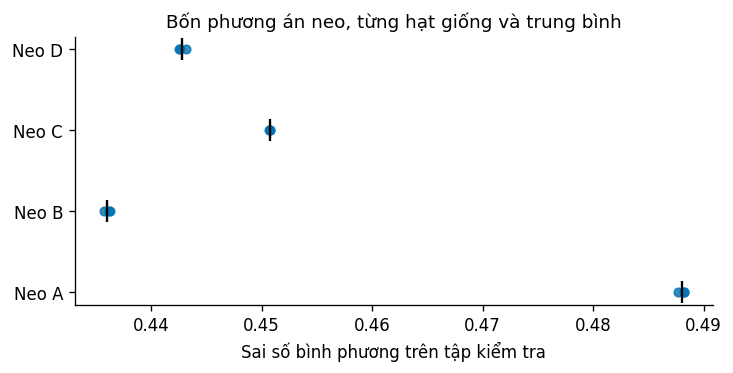

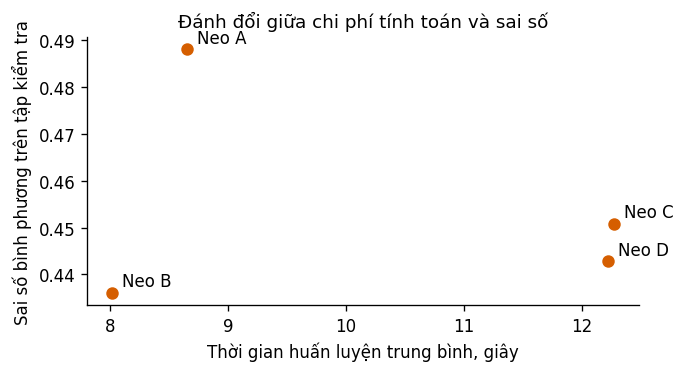

In [11]:
fig, ax = plt.subplots(figsize=(6.0, 3.0))
for i, neo in enumerate(NEO):
    v = np.array(tong_hop[neo]["cac_gia_tri_mse"])
    ax.scatter(v, np.full_like(v, i, dtype=float), s=26, color=PALETTE[0], alpha=0.8, zorder=3)
    ax.scatter([v.mean()], [i], marker="|", s=170, color="black", zorder=4)
ax.set_yticks(range(len(NEO)))
ax.set_yticklabels(["Neo " + n for n in NEO])
ax.set_xlabel("Sai số bình phương trên tập kiểm tra")
ax.set_title("Bốn phương án neo, từng hạt giống và trung bình")
luu_hinh(fig, "fig12_sai_so_bon_phuong_an_neo.png")

fig, ax = plt.subplots(figsize=(5.6, 3.0))
x = [tong_hop[n]["giay_trung_binh"] for n in NEO]
y = [tong_hop[n]["mse_trung_binh"] for n in NEO]
ax.scatter(x, y, s=42, color=PALETTE[1], zorder=3)
for i, n in enumerate(NEO):
    ax.annotate("Neo " + n, (x[i], y[i]), textcoords="offset points", xytext=(6, 4))
ax.set_xlabel("Thời gian huấn luyện trung bình, giây")
ax.set_ylabel("Sai số bình phương trên tập kiểm tra")
ax.set_title("Đánh đổi giữa chi phí tính toán và sai số")
luu_hinh(fig, "fig13_chi_phi_doi_sai_so.png")

In [12]:
bao_cao = {"kiem_tra_luc": datetime.datetime.now().isoformat(timespec="seconds"),
           "read_tag": READ_TAG, "run_tag": RUN_TAG,
           "giao_thuc": meta["protocol"], "n_seeds": N_SEEDS,
           "tong_hop": tong_hop, "thu_tu_tot_den_kem": thu_tu,
           "bat_cap_theo_benh_nhan": so_sanh, "env": ENV}
(RUN_DIR / "W2_so_sanh_bon_phuong_an_neo.json").write_text(
    json.dumps(bao_cao, ensure_ascii=False, indent=2))
print("Đã ghi", RUN_DIR / "W2_so_sanh_bon_phuong_an_neo.json")

Đã ghi /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/bo_sung_04_neo_abcd/W2_so_sanh_bon_phuong_an_neo.json


## 6. Cách đọc kết quả

- Thứ tự bốn phương án neo là kết quả chính. Nếu B không tốt hơn A thì giả thuyết của đề tài bị thách thức ngay trong tuần 2, và sổ tay `W2_05_Trung_Neo_Giao_Thuc_Su_Kien` sẽ cho biết nguyên nhân có phải do hai phương án neo trùng nhau quá nhiều hay không.
- Hình thứ hai dùng cho phần thảo luận về chi phí. Một phương án neo đắt hơn chỉ đáng chọn nếu sai số giảm nhiều hơn phần chi phí tăng thêm.
- Số tham số của A, B và C gần như bằng nhau, nên mọi khác biệt về sai số không thể quy cho dung lượng mô hình.